<a href="https://colab.research.google.com/github/Abdoulaye279/Financial-Engineering/blob/main/black-scholes-sp500/01_assumptions.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 01 - Black-Scholes assumptions on the S&P 500

BS assumes a geometric Brownian motion: normal log returns and a constant volatility. Checked on daily closes since 2000.

In [1]:
# colab: get the repo first
try:
    import google.colab
    !git clone -q https://github.com/Abdoulaye279/Financial-Engineering
    %cd Financial-Engineering/black-scholes-sp500
except ImportError:
    pass

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from pricing import black_scholes, monte_carlo, binomial_crr, implied_vol
plt.style.use("quant.mplstyle")

df = pd.read_csv("data/sp500.csv")
df["Date"] = pd.to_datetime(df["Date"].str[:10])
prices = df.set_index("Date")["Close"].loc["2000":]
rets = np.log(prices).diff().dropna()

S0 = prices.iloc[-1]
sigma = rets.std() * np.sqrt(252)   # historical vol since 2000
r, T = 0.03, 21 / 252               # 3% rate, 1 month
print(len(rets), "days", rets.index[0].date(), "->", rets.index[-1].date(), "| S0", round(S0, 2), "| vol", round(sigma, 4))

6761 days 2000-01-04 -> 2026-11-19 | S0 7175.83 | vol 0.1924


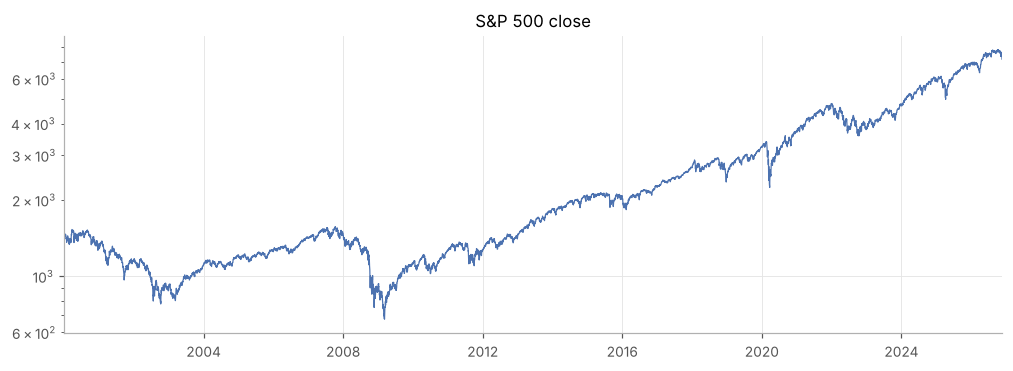

In [3]:
plt.figure(figsize=(11, 3.5))
plt.plot(prices, lw=0.8)
plt.yscale("log")
plt.xlim(prices.index[0], prices.index[-1])
plt.title("S&P 500 close")
plt.show()

In [4]:
z = (rets - rets.mean()) / rets.std()
print("skew", round(stats.skew(rets), 2), " excess kurtosis", round(stats.kurtosis(rets), 2))
print("jarque-bera p", stats.jarque_bera(rets).pvalue, " KS p", stats.kstest(z, "norm").pvalue)
print("days beyond 4 sd:", (abs(z) > 4).sum(), " normal law:", round(len(z) * 2 * stats.norm.sf(4), 1))
print("worst day", round(rets.min(), 3), rets.idxmin().date(), round(z.min(), 1), "sd")
# normality rejected by both tests. kurtosis ~10 instead of 0 -> fat tails
# 46 days beyond 4 sd when the normal law gives less than 1. march 2020 = -10.6 sd, basically impossible if normal
# negative skew: big drops more frequent than big rises

skew -0.35  excess kurtosis 10.64
jarque-bera p 0.0  KS p 6.172141174321856e-52
days beyond 4 sd: 46  normal law: 0.4
worst day -0.128 2020-03-16 -10.6 sd


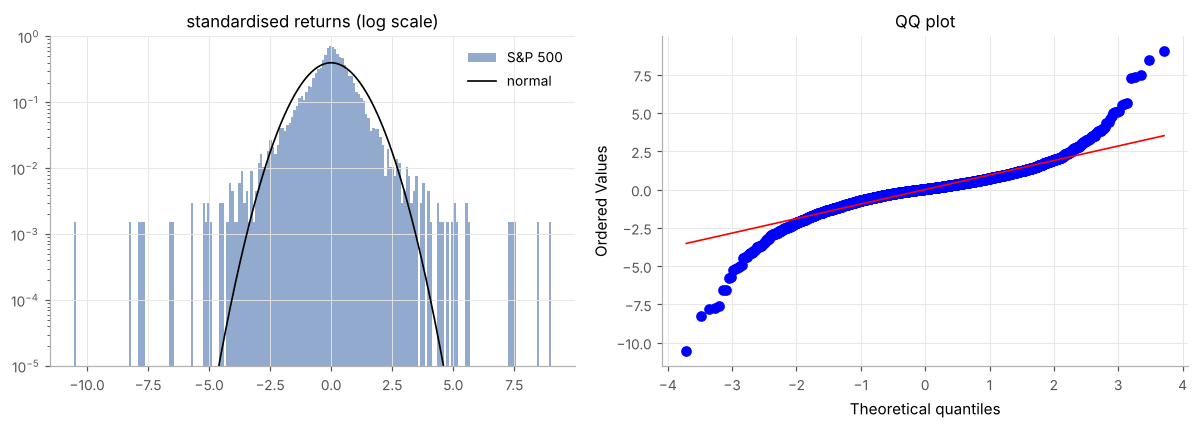

In [5]:
x = np.linspace(z.min(), z.max(), 400)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].hist(z, bins=200, density=True, alpha=0.6, label="S&P 500")
ax[0].plot(x, stats.norm.pdf(x), "k", label="normal")
ax[0].set_yscale("log"); ax[0].set_ylim(1e-5, 1); ax[0].set_title("standardised returns (log scale)"); ax[0].legend()
stats.probplot(z, dist="norm", plot=ax[1])
ax[1].set_title("QQ plot")
plt.tight_layout()
plt.show()

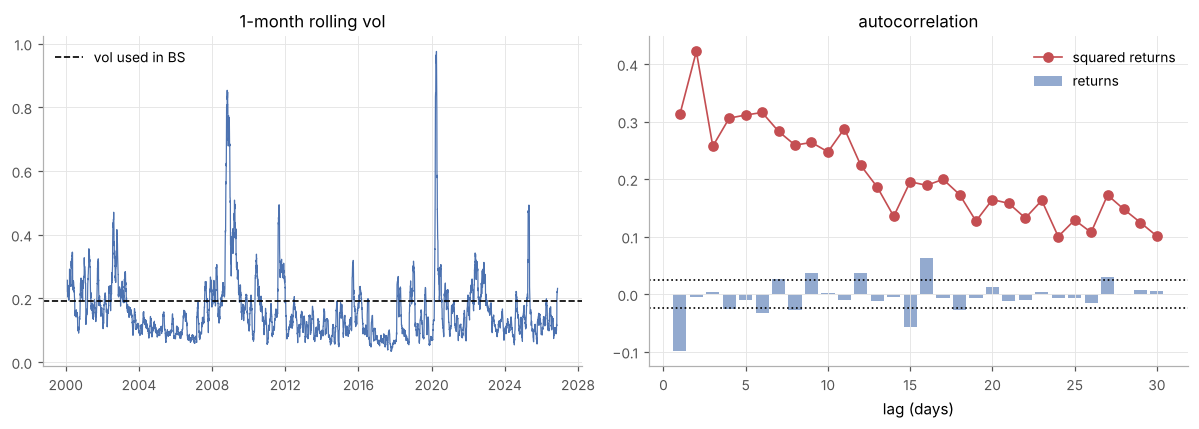

vol min 0.035 2017-10-11  max 0.976 2020-04-06


In [6]:
vol = rets.rolling(21).std() * np.sqrt(252)
acf = lambda x, k: np.corrcoef(x[:-k], x[k:])[0, 1]
lags = range(1, 31)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(vol, lw=0.8)
ax[0].axhline(sigma, color="k", ls="--", label="vol used in BS")
ax[0].set_title("1-month rolling vol"); ax[0].legend()
ax[1].bar(lags, [acf(rets.values, k) for k in lags], alpha=0.6, label="returns")
ax[1].plot(lags, [acf(rets.values ** 2, k) for k in lags], "o-", color="C3", label="squared returns")
for s in (1, -1):
    ax[1].axhline(s * 1.96 / np.sqrt(len(rets)), color="k", ls=":")
ax[1].set_title("autocorrelation"); ax[1].set_xlabel("lag (days)"); ax[1].legend()
plt.tight_layout()
plt.show()
print("vol min", round(vol.min(), 3), vol.idxmin().date(), " max", round(vol.max(), 3), vol.idxmax().date())
# vol not constant at all: ~3% in 2017, ~98% in april 2020, spikes in 2008 and 2020
# returns barely autocorrelated but squared returns stay correlated for weeks = vol clustering
# -> both BS assumptions are wrong for the S&P 500